In [14]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [15]:
import os
os.environ['CUDA_VISIBLE_DEVICES'] = '7'

In [16]:
import functools
from functools import partial
import itertools
import pprint

import orbax.checkpoint
import numpy as np
import jax
import jax.numpy as jnp
import torch.utils.data.dataloader
import sqlalchemy as sa
import seaborn as sns
sns.set_theme(style='whitegrid', font_scale=1.4, palette=sns.color_palette(),)
import pandas as pd
import matplotlib.pyplot as plt
import duckdb
import polars as pl
import diffrax
import spt_guidance.jax

import conf.conf
import conf.model
import userfm.datasets
import userfm.event_constraints
import userfm.main
import userfm.utils
import userfm.unet

In [17]:
duckdb.sql("""
attach '../runs.sqlite';
use runs;
""")

BinderException: Binder Error: Failed to attach database: database with name "runs" already exists

In [ ]:
session = conf.conf.Session()
session.begin()

In [ ]:
dataset_rows = duckdb.sql("""
select
    *
from Dataset
join GaussianMixture on Dataset.id = GaussianMixture.id
""")
dataset_rows

In [ ]:
dataset_rows = duckdb.sql("""
select
    *
from Dataset
join DynamicalSystem on Dataset.id = DynamicalSystem.id
join Lorenz63 on Dataset.id = Lorenz63.id
where time_step_count = 90 and batch_count_train = 8
""")
dataset_rows

In [ ]:
model_rows = duckdb.sql("""
select
    *
from Model
join FlowMatching on Model.id = FlowMatching.id
join ProbabilityPath on FlowMatching.ProbabilityPath = ProbabilityPath.id
join VarianceExploding on ProbabilityPath.id = VarianceExploding.id
where finzi_karras_weighting
""")
model_rows.show(max_width=120)

In [ ]:
rows = duckdb.sql("""
select
    *
from Conf
join TrainingAndEvaluation on Conf.id = TrainingAndEvaluation.id
join dataset_rows on TrainingAndEvaluation.Dataset = dataset_rows.id
join model_rows on TrainingAndEvaluation.Model = model_rows.id
join Steering on TrainingAndEvaluation.Steering = Steering.id
where sampling_step_count = 1000
""")
rows.show(max_width=120)

In [ ]:
cfgs = session.query(conf.conf.TrainingAndEvaluation).where(conf.conf.Conf.alt_id.in_(rows.pl()['alt_id'].to_list())).all()
info = {c.alt_id: dict(cfg=c) for c in cfgs}
cfg = cfgs[0]

In [ ]:
splits = ('train', 'val', 'test')
(
    *key_dataset_splits,
    key_jax_lightning,
    key_samples,
) = jax.random.split(
    jax.random.key(userfm.utils.RNG_RANDBITS[cfg.rng_seed]),
    len(splits) + 2
)

In [18]:
splits = {
    s: userfm.datasets.get_dataset(cfg.dataset, k, batch_count)
    for s, k in zip(splits, key_dataset_splits)
    if (batch_count := getattr(cfg.dataset, f'batch_count_{s}')) > 0
}
train_data_std = splits['train'][:].std()
dataloaders = {
    split: torch.utils.data.DataLoader(
        v,
        batch_sampler=torch.utils.data.BatchSampler(
            torch.utils.data.SequentialSampler(v),
            cfg.dataset.batch_size, drop_last=True,
        ),
        collate_fn=lambda x: x,
    )
    for split, v in splits.items()
}
dataloaders['predict'] = dataloaders.get(cfg.predict_split)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  1.16it/s]


In [19]:
# DO NOT EXECUTE UNTIL ALL PREVIOUS CELLS HAVE FINISHED EXECUTING; ELSE GET ASYNC ERRORS.
orbax_checkpointer = orbax.checkpoint.PyTreeCheckpointer()
x_sample = next(iter(dataloaders['train']))
cfg_info = {}
reference_cfg = cfg
ckpt = 'last'
for v in info.values():
    cfg = v['cfg']
    assert cfg.rng_seed == reference_cfg.rng_seed
    assert cfg.dataset == reference_cfg.dataset
    cfg_unet = userfm.unet.unet_64_config(
        splits['train'][:1].shape[2],
        base_channels=cfg.model.base_channel_count,
        attention=cfg.model.use_attention,
    )
    model = userfm.unet.UNet(cfg_unet)
    jax_lightning = userfm.main.JaxLightning(cfg, key_jax_lightning, dataloaders, train_data_std, model)
    jax_lightning.params = orbax_checkpointer.restore(cfg.run_dir/ckpt)
    jax_lightning.params_ema = orbax_checkpointer.restore(cfg.run_dir/f'{ckpt}_ema')
    v['jax_lightning'] = jax_lightning

/home/ttransue/GitHub/Aligning-Flow-Div-User-Defined-Sampling/.venv/lib/python3.13/site-packages/orbax/checkpoint/_src/serialization/jax_array_handlers.py:711: UserWarning: Sharding info not provided when restoring. Populating sharding info from sharding file. Please note restoration time will be slightly increased due to reading from file. Note also that this option is unsafe when restoring on a different topology than the checkpoint was saved with.
  warnings.warn(


In [20]:
evaluation_trajectories = next(iter(dataloaders['val']))

In [21]:
for v in info.values():
    times = v['jax_lightning'].get_sample_times(100)
    v['samples'] = v['jax_lightning'].sample(times[0], times[-1], times[1] - times[0], v['jax_lightning'].noise_std * jax.random.normal(key_samples, evaluation_trajectories.shape))

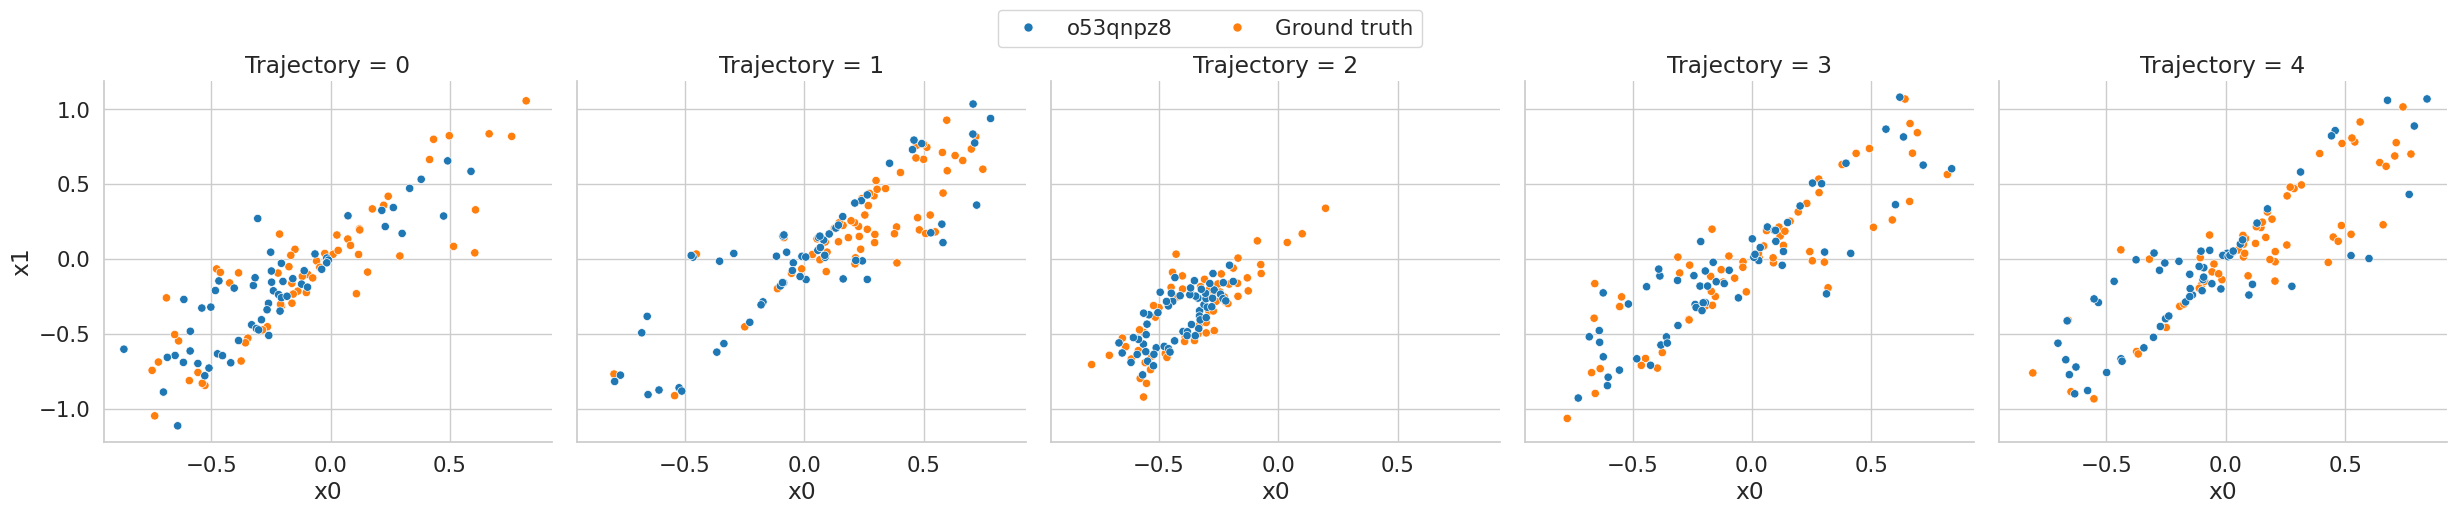

In [22]:
trajectory_count = 5
if evaluation_trajectories.shape[2] > 1:
    df = pd.concat([
        *[
            pd.DataFrame(dict(
                Source='Ground truth', Trajectory=str(i), x0=evaluation_trajectories[i, :, 0], x1=evaluation_trajectories[i, :, 1]
            ))
            for i in range(trajectory_count)
        ],
        *itertools.chain.from_iterable([
            [
                pd.DataFrame(dict(
                    Source=k, Trajectory=str(i), x0=v['samples'].ys[-1, i, :, 0], x1=v['samples'].ys[-1, i, :, 1]
                ))
                for i in range(trajectory_count)
            ]
            for k, v in info.items()
        ])
    ]).reset_index(names=['Time Step'])
    share_axes = True
    center_axes = False
    plot = sns.relplot(
        data=df,
        x='x0', y='x1',
        hue='Source',
        hue_order=[*info, 'Ground truth'],
        col='Trajectory',
        facet_kws=dict(
            sharex=share_axes,
            sharey=share_axes,
        )
    )
    xmax, ymax = df[['x0', 'x1']].max(axis=0) + .4
    for (row, col, hue), data in plot.facet_data():
        ax = plot.axes[row][col]
        if not share_axes:
            xmax, ymax = data[['x0', 'x1']].max(axis=0) + .4
        if center_axes:
            ax.set_xlim(xmin=-xmax, xmax=xmax)
            ax.set_ylim(ymin=-ymax, ymax=ymax)
            ax.set_aspect('equal')
            ax.plot([0], [0], 'kx')
    sns.move_legend(
        plot,
        loc='upper center',
        ncol=len(info) + 1,
        title='',
        # labels=[],
        bbox_to_anchor=(.455, 1.06),
        frameon=True,
        fancybox=True,
    )
else:
    df = pd.concat([
        *[
            pd.DataFrame(dict(
                Source='Ground truth', Trajectory=str(i), x0=evaluation_trajectories[i, :, 0],
            ))
            for i in range(trajectory_count)
        ],
        *itertools.chain.from_iterable([
            [
                pd.DataFrame(dict(
                    Source=k, Trajectory=str(i), x0=v['samples'].ys[-1, i, :, 0],
                ))
                for i in range(trajectory_count)
            ]
            for k, v in info.items()
        ])
    ]).reset_index(names=['Time Step'])
    plot = sns.displot(
        kind='kde',
        data=df,
        x='x0',
        col='Source',
        col_order=[*info, 'Ground truth'],
        hue='Trajectory',
        common_norm=False,
    )

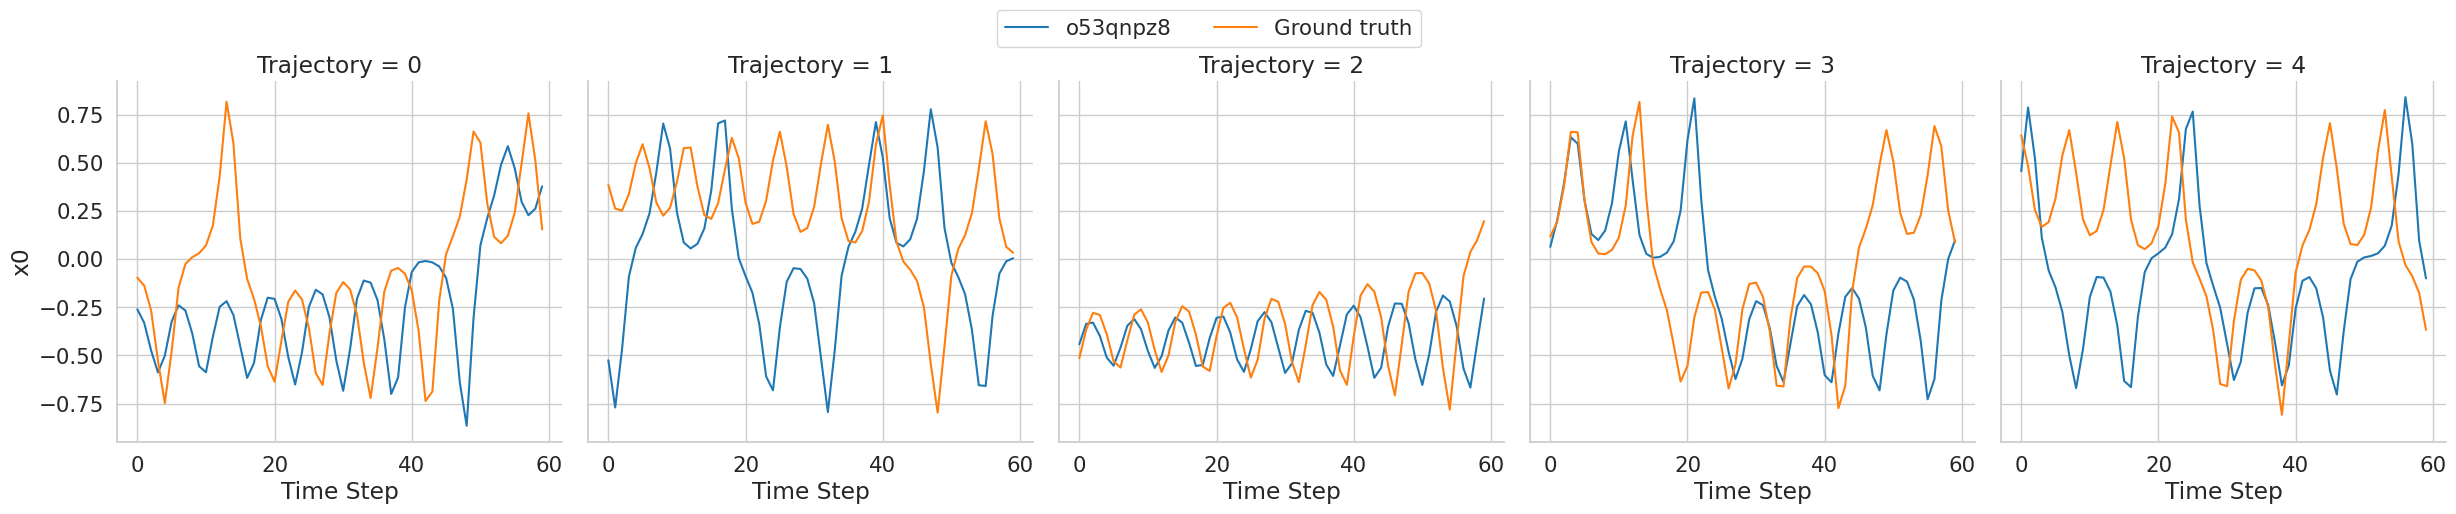

In [23]:
if evaluation_trajectories.shape[2] > 1:
    plot = sns.relplot(
        kind='line',
        data=df,
        x='Time Step',
        y='x0',
        hue='Source',
        hue_order=[*info, 'Ground truth'],
        col='Trajectory'
    )
    sns.move_legend(
        plot,
        loc='upper center',
        ncol=len(info) + 1,
        title='',
        # labels=[],
        bbox_to_anchor=(.455, 1.06),
        frameon=True,
        fancybox=True,
    )
else:
    plot = (
        sns.displot(
            kind='hist',
            stat='density',
            data=df,
            x='x0',
            row='Source',
            row_order=info.keys(),
            col='Trajectory',
            hue='Source',
            hue_order=info.keys(),
            bins=50,
            common_norm=False,
        )
    )

In [24]:
trajectory_count = 5
if evaluation_trajectories.shape[2] == 1:
    df = pd.concat([
        *itertools.chain.from_iterable([
            [
                pd.DataFrame(v['samples'].ys[:, i, :, 0]).T
                # pd.DataFrame(dict(
                #     Source=config_alt_ids[config_alt_id], Trajectory=str(i), x0=v['samples'][:, i, :, 0],
                # ))
                for i in range(trajectory_count)
            ]
            for v in info.values()
        ])
    ], keys=itertools.product(info.keys(), range(trajectory_count)), names=['Source', 'Trajectory'])
    for k, v in info.items():
        if isinstance(v['cfg'].model.probability_path, conf.model.VarianceExploding):
            sigma = jax.vmap(v['jax_lightning'].diffusion.sigma)(jnp.linspace(0, 1, df.shape[1])[::-1])
            # sigma = jnp.where(jnp.arange(df.shape[1]) <= 467, sigma, 1)
            sigma = sigma.clip(min=1)  # heuristic
            df.loc[[k]] = df.loc[[k]] / pd.Series(sigma)
    df = df.melt(var_name='Time', value_name='Value', ignore_index=False).reset_index()
    plot = sns.displot(
        data=df,
        x='Time',
        y='Value',
        row='Source',
        row_order=info.keys(),
        col='Trajectory',
        hue='Source',
        hue_order=info.keys(),
        bins=50,
        common_norm=False,
        common_bins=False,
        facet_kws=dict(
            # sharex=False,
            sharey='row',
        ),
    )

In [ ]:
# session.close()